# CDS 4003: Mobile Game In-App Purchases
## Stage 5: Model Selection and Development
**Models Implemented:** Decision Tree, XGBoost, Random Forest, and NLP (Tabular-to-Text TF-IDF + Logistic Regression)



## Shared data preparation and evaluation

All models use the same explicit profile/session predictor list and the same stratified train/test split. Imputation and categorical encoding are fitted inside each model pipeline and within each cross-validation fold.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix
)

RANDOM_STATE = 42
DATA_PATH = "mobile_game_players_eda_features.csv"
TARGET = "SpendingSegment"
LABELS = ["Minnow", "Dolphin", "Whale"]
FEATURE_COLS = ["Age", "Country", "Device", "GameGenre", "SessionCount", "AverageSessionLength"]

# Keep predictors explicit so derived or simulated helper fields cannot enter silently.
df = pd.read_csv(DATA_PATH).drop_duplicates().copy()
missing_columns = [c for c in FEATURE_COLS + [TARGET] if c not in df.columns]
if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")
df = df.dropna(subset=[TARGET]).loc[lambda data: data[TARGET].isin(LABELS)].copy()
X = df[FEATURE_COLS].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

categorical_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", SimpleImputer(strategy="median"), numeric_cols),
        ("categorical", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_cols),
    ],
    remainder="drop",
)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

print(f"Rows used: {len(df):,}")
print("Predictors:", FEATURE_COLS)
print("Target distribution:")
print(y.value_counts().reindex(LABELS))

# Use one evaluator so all candidate models and the baseline report comparable metrics.
def evaluate_model(name, y_true, predictions, make_plot=True):
    scores = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_true, predictions),
        "Macro-F1": f1_score(y_true, predictions, average="macro"),
    }
    print(pd.Series(scores).to_string(index=False))
    print("\nClassification report:")
    print(classification_report(y_true, predictions, labels=LABELS, digits=4, zero_division=0))
    if make_plot:
        cm = confusion_matrix(y_true, predictions, labels=LABELS)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS)
        plt.title(f"{name} — test confusion matrix")
        plt.xlabel("Predicted segment")
        plt.ylabel("Actual segment")
        plt.tight_layout()
        plt.show()
    return scores



def plot_importance(series, title, xlabel, cmap="viridis", figsize=(9, 5)):
    ordered = series.sort_values(ascending=True)
    colors = plt.get_cmap(cmap)(np.linspace(0.18, 0.88, len(ordered)))
    ax = ordered.plot.barh(figsize=figsize, color=colors)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Feature")
    plt.tight_layout()
    plt.show()

Rows used: 247,500
Predictors: ['Age', 'Country', 'Device', 'GameGenre', 'SessionCount', 'AverageSessionLength']
Target distribution:
SpendingSegment
Minnow     208328
Dolphin     33670
Whale        5502
Name: count, dtype: int64


## Model 1: Decision Tree Classifier

A Decision Tree creates a sequence of feature-based splits and is included as an interpretable model. Gini and Entropy are compared as preliminary un-tuned settings; GridSearchCV then selects tree depth and leaf size using training folds only. Macro-F1 is used for model selection because it gives each spending segment equal weight.

The predictor list is explicit. It uses baseline profile and session variables, and excludes identifiers, direct spending fields, EDA helper variables, and simulated 30-day fields that may encode the target-generation assumptions. The models therefore assess a narrower, more defensible predictor set. As the source data are generated, results still require cautious interpretation and do not establish performance on live players.

In [2]:
# Fit the two preliminary Decision Tree criteria on the shared training split.
gini_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", DecisionTreeClassifier(criterion="gini", class_weight="balanced", random_state=RANDOM_STATE)),
])
gini_pipeline.fit(X_train, y_train)
y_pred_gini = gini_pipeline.predict(X_test)

Decision Tree — Gini (untuned)
                      0.946202
                      0.862316
                      0.866511

Classification report:
              precision    recall  f1-score   support

      Minnow     0.9674    0.9707    0.9690     41666
     Dolphin     0.8345    0.8190    0.8267      6734
       Whale     0.8105    0.7973    0.8038      1100

    accuracy                         0.9462     49500
   macro avg     0.8708    0.8623    0.8665     49500
weighted avg     0.9458    0.9462    0.9460     49500



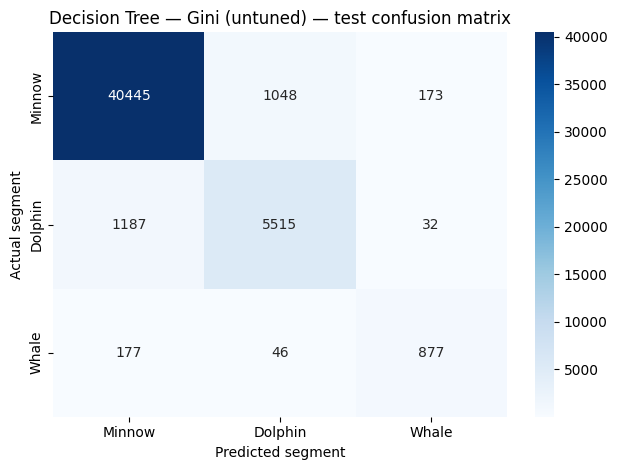

In [3]:
# Test-set results: Decision Tree with Gini criterion.
gini_scores = evaluate_model("Decision Tree — Gini (untuned)", y_test, y_pred_gini)

In [4]:
# Fit the preliminary Decision Tree using Entropy.
entropy_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", DecisionTreeClassifier(criterion="entropy", class_weight="balanced", random_state=RANDOM_STATE)),
])
entropy_pipeline.fit(X_train, y_train)
y_pred_entropy = entropy_pipeline.predict(X_test)

Decision Tree — Entropy (untuned)
                         0.942889
                         0.858477
                         0.860312

Classification report:
              precision    recall  f1-score   support

      Minnow     0.9667    0.9670    0.9669     41666
     Dolphin     0.8181    0.8184    0.8183      6734
       Whale     0.8017    0.7900    0.7958      1100

    accuracy                         0.9429     49500
   macro avg     0.8622    0.8585    0.8603     49500
weighted avg     0.9428    0.9429    0.9429     49500



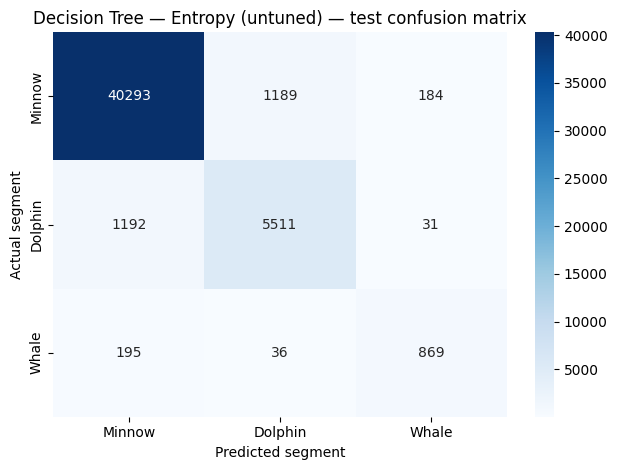

In [5]:
# Test-set results: Decision Tree with Entropy criterion.
entropy_scores = evaluate_model("Decision Tree — Entropy (untuned)", y_test, y_pred_entropy)

In [6]:
# Tune Decision Tree hyperparameters using cross-validation on training data only.
param_grid = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [5, 10, 15],
    "model__min_samples_leaf": [10, 50, 100],
}
dt_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
])
dt_search = GridSearchCV(dt_pipeline, param_grid, scoring="f1_macro", cv=cv, n_jobs=-1, refit=True)
dt_search.fit(X_train, y_train)
best_dt = dt_search.best_estimator_
print("Best Decision Tree parameters:", dt_search.best_params_)
print("Best cross-validation Macro-F1:", round(dt_search.best_score_, 4))
y_pred_dt = best_dt.predict(X_test)

Best Decision Tree parameters: {'model__criterion': 'gini', 'model__max_depth': 15, 'model__min_samples_leaf': 10}
Best cross-validation Macro-F1: 0.4046


Decision Tree — tuned
              0.58604
             0.656828
             0.424868

Classification report:
              precision    recall  f1-score   support

      Minnow     0.9304    0.5930    0.7243     41666
     Dolphin     0.3650    0.4948    0.4201      6734
       Whale     0.0703    0.8827    0.1302      1100

    accuracy                         0.5860     49500
   macro avg     0.4552    0.6568    0.4249     49500
weighted avg     0.8343    0.5860    0.6697     49500



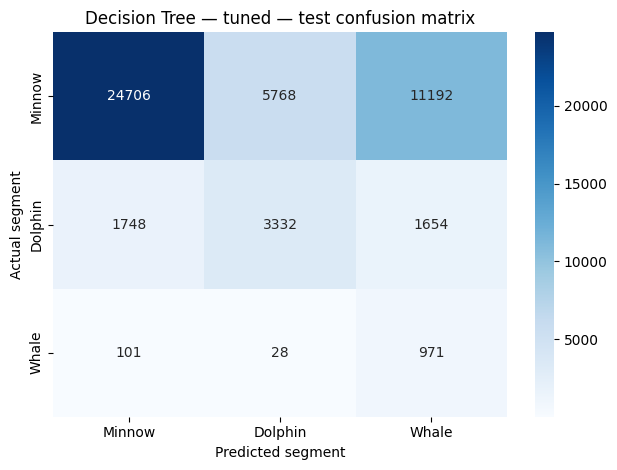

In [7]:
# Test-set results: tuned Decision Tree.
dt_scores = evaluate_model("Decision Tree — tuned", y_test, y_pred_dt)

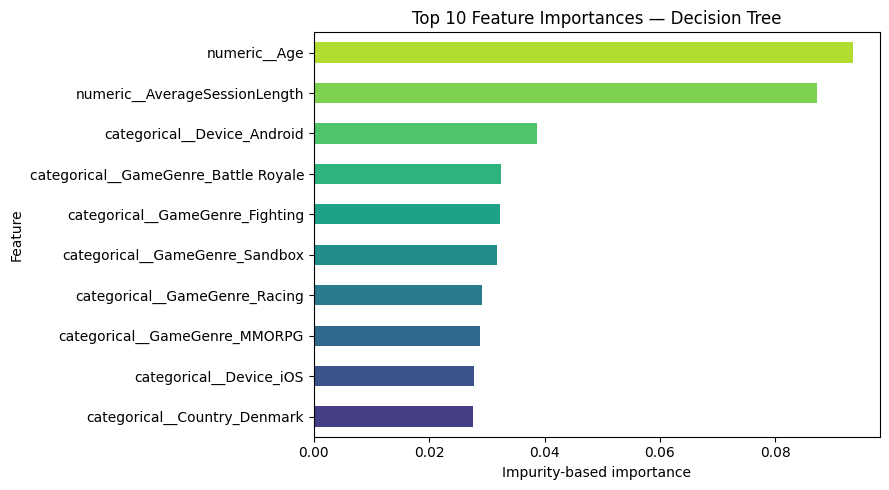

In [8]:
# Decision Tree feature importance (descriptive, not causal).
dt_names = best_dt.named_steps["preprocess"].get_feature_names_out()
dt_importance = pd.Series(
    best_dt.named_steps["model"].feature_importances_, index=dt_names
).sort_values(ascending=False).head(10)
plot_importance(dt_importance, "Top 10 Feature Importances — Decision Tree", "Impurity-based importance", cmap="viridis")

## Decision Tree Results & Insights

Use the recalculated test-set metrics and class-level report above when writing the results. Macro-F1 and Balanced Accuracy are more informative than accuracy alone for this imbalanced target. Whale and Dolphin recall should be read together with their precision: high recall can still involve many false positives. Feature importance is not evidence that a variable causes spending.

## Model 2: XGBoost Classifier

XGBoost builds trees sequentially. It is suitable for structured data with non-linear relationships. The same predictor set, split, preprocessing, and Macro-F1 objective are used to make the comparison consistent. Balanced sample weights are computed from the training labels. The encoder and imputer are fitted inside each cross-validation training fold through the pipeline.

In [9]:
# Fit an untuned XGBoost reference model before hyperparameter tuning.
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

label_to_int = {label: i for i, label in enumerate(LABELS)}
int_to_label = {i: label for label, i in label_to_int.items()}
y_train_int = y_train.map(label_to_int)
y_test_int = y_test.map(label_to_int)
xgb_reference = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", XGBClassifier(
        objective="multi:softprob", num_class=len(LABELS), eval_metric="mlogloss",
        tree_method="hist", max_depth=5, n_estimators=50,
        random_state=RANDOM_STATE, n_jobs=1,
    )),
])
reference_weights = compute_sample_weight(class_weight="balanced", y=y_train_int)
xgb_reference.fit(X_train, y_train_int, model__sample_weight=reference_weights)
reference_pred_int = xgb_reference.predict(X_test).astype(int)
reference_pred = pd.Series(reference_pred_int).map(int_to_label).to_numpy()

XGBoost — untuned reference
                   0.709293
                   0.806147
                   0.536273

Classification report:
              precision    recall  f1-score   support

      Minnow     0.9653    0.6933    0.8070     41666
     Dolphin     0.3886    0.7679    0.5160      6734
       Whale     0.1680    0.9573    0.2858      1100

    accuracy                         0.7093     49500
   macro avg     0.5073    0.8061    0.5363     49500
weighted avg     0.8691    0.7093    0.7558     49500



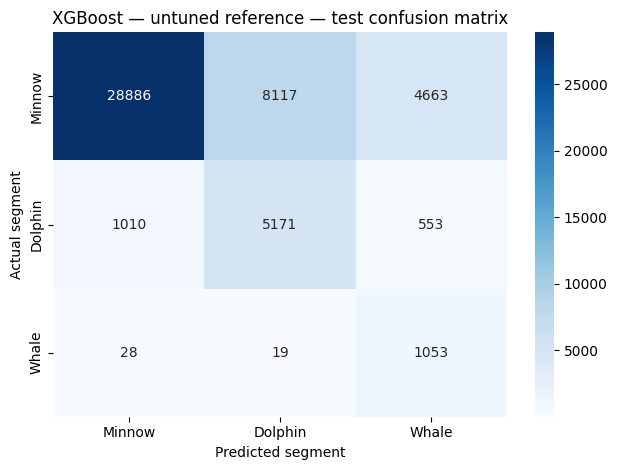

In [10]:
# Test-set results: untuned XGBoost reference.
xgb_reference_scores = evaluate_model("XGBoost — untuned reference", y_test, reference_pred)

In [11]:
# Tune XGBoost on training folds using Macro-F1.
xgb_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", XGBClassifier(
        objective="multi:softprob", num_class=len(LABELS), eval_metric="mlogloss",
        tree_method="hist", random_state=RANDOM_STATE, n_jobs=1,
    )),
])
xgb_params = {
    "model__max_depth": [3, 5, 7],
    "model__n_estimators": [50, 100],
}
xgb_weights = compute_sample_weight(class_weight="balanced", y=y_train_int)
xgb_search = GridSearchCV(xgb_pipeline, xgb_params, scoring="f1_macro", cv=cv, n_jobs=-1, refit=True)
xgb_search.fit(X_train, y_train_int, model__sample_weight=xgb_weights)
best_xgb = xgb_search.best_estimator_
print("Best XGBoost parameters:", xgb_search.best_params_)
print("Best cross-validation Macro-F1:", round(xgb_search.best_score_, 4))
xgb_pred_int = best_xgb.predict(X_test).astype(int)
y_pred_xgb = pd.Series(xgb_pred_int).map(int_to_label).to_numpy()

Best XGBoost parameters: {'model__max_depth': 7, 'model__n_estimators': 100}
Best cross-validation Macro-F1: 0.7807


XGBoost — tuned
       0.881455
       0.918827
       0.765134

Classification report:
              precision    recall  f1-score   support

      Minnow     0.9894    0.8712    0.9266     41666
     Dolphin     0.5889    0.9335    0.7222      6734
       Whale     0.4897    0.9518    0.6467      1100

    accuracy                         0.8815     49500
   macro avg     0.6893    0.9188    0.7651     49500
weighted avg     0.9238    0.8815    0.8925     49500



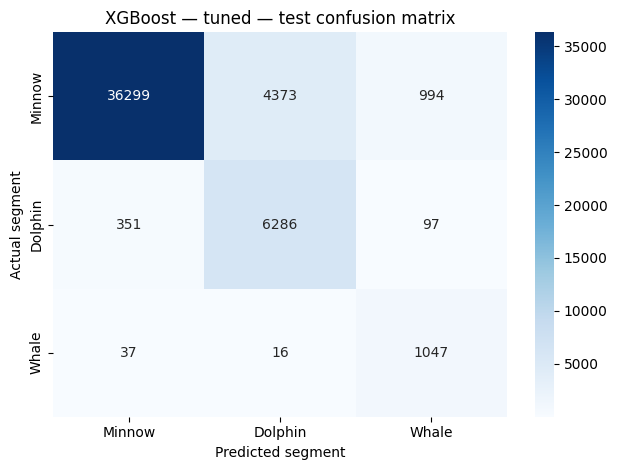

In [12]:
# Test-set results: tuned XGBoost, decoded to the original segment names.
xgb_scores = evaluate_model("XGBoost — tuned", y_test, y_pred_xgb)

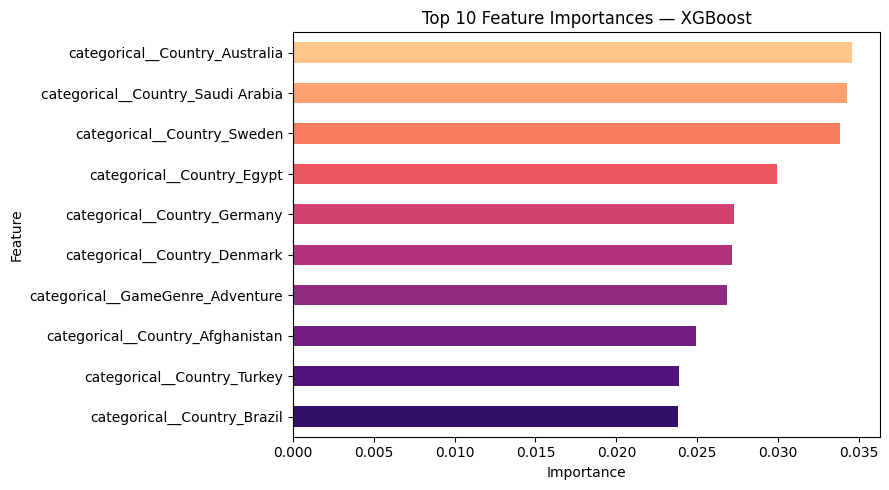

In [13]:
# XGBoost feature importance (descriptive, not causal).
xgb_names = best_xgb.named_steps["preprocess"].get_feature_names_out()
xgb_importance = pd.Series(
    best_xgb.named_steps["model"].feature_importances_, index=xgb_names
).sort_values(ascending=False).head(10)
plot_importance(xgb_importance, "Top 10 Feature Importances — XGBoost", "Importance", cmap="magma")

## XGBoost Results & Insights

A higher Whale recall is useful for identifying more high-spending players, but its practical value depends on the corresponding precision and the cost of unnecessary offers. Classification performance does not by itself demonstrate campaign effectiveness or increased revenue.

## Model 3: Random Forest Classifier

Random Forest combines predictions from many decision trees, reducing the reliance on any one tree and capturing non-linear patterns. Class-balanced weights address the imbalance among Minnow, Dolphin, and Whale labels. A baseline forest is evaluated before RandomizedSearchCV. Preprocessing is part of the pipeline, so imputation and one-hot encoding are learned separately within every cross-validation fold.

In [14]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix
)

RANDOM_STATE = 42
DATA_PATH = "mobile_game_players_eda_features.csv"
TARGET = "SpendingSegment"
LABELS = ["Minnow", "Dolphin", "Whale"]
FEATURE_COLS = ["Age", "Country", "Device", "GameGenre", "SessionCount", "AverageSessionLength"]

df = pd.read_csv(DATA_PATH).drop_duplicates().copy()
missing_columns = [c for c in FEATURE_COLS + [TARGET] if c not in df.columns]
if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")
df = df.dropna(subset=[TARGET]).loc[lambda data: data[TARGET].isin(LABELS)].copy()
X = df[FEATURE_COLS].copy()
y = df[TARGET].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
categorical_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", SimpleImputer(strategy="median"), numeric_cols),
        ("categorical", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_cols),
    ],
    remainder="drop",
)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

def evaluate_model(name, y_true, predictions, make_plot=True):
    scores = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_true, predictions),
        "Macro-F1": f1_score(y_true, predictions, average="macro"),
    }
    print(pd.Series(scores).to_string(index=False))
    print("\nClassification report:")
    print(classification_report(y_true, predictions, labels=LABELS, digits=4, zero_division=0))
    if make_plot:
        cm = confusion_matrix(y_true, predictions, labels=LABELS)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS)
        plt.title(f"{name} — test confusion matrix")
        plt.xlabel("Predicted segment")
        plt.ylabel("Actual segment")
        plt.tight_layout()
        plt.show()
    return scores

print(f"Rows used: {len(df):,}")
print("Predictors:", FEATURE_COLS)
print("Target distribution:")
print(y.value_counts().reindex(LABELS))

Rows used: 247,500
Predictors: ['Age', 'Country', 'Device', 'GameGenre', 'SessionCount', 'AverageSessionLength']
Target distribution:
SpendingSegment
Minnow     208328
Dolphin     33670
Whale        5502
Name: count, dtype: int64


In [15]:
# Baseline Random Forest and training-fold cross-validation
rf_baseline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=80, max_depth=15, min_samples_leaf=5,
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1,
    )),
])
cv_scores = cross_val_score(rf_baseline, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
print(f"Baseline RF 3-fold CV Macro-F1: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")
rf_baseline.fit(X_train, y_train)
y_pred_rf_base = rf_baseline.predict(X_test)

Baseline RF 3-fold CV Macro-F1: 0.7090 (+/- 0.0183)


Random Forest — baseline
                0.860889
                0.878392
                0.675272

Classification report:
              precision    recall  f1-score   support

      Minnow     0.9827    0.8640    0.9195     41666
     Dolphin     0.6837    0.8285    0.7492      6734
       Whale     0.2203    0.9427    0.3572      1100

    accuracy                         0.8609     49500
   macro avg     0.6289    0.8784    0.6753     49500
weighted avg     0.9251    0.8609    0.8838     49500



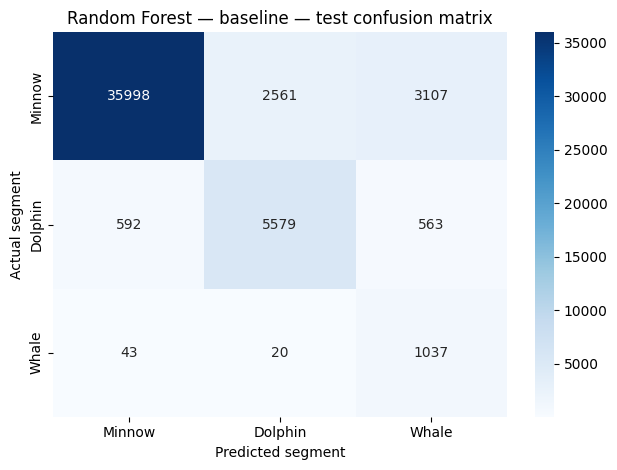

In [16]:
rf_base_scores = evaluate_model("Random Forest — baseline", y_test, y_pred_rf_base)

In [17]:
# Tune a compact parameter space using training folds only.
rf_params = {
    "model__n_estimators": [80, 120],
    "model__max_depth": [10, 15, 20],
    "model__min_samples_split": [5, 10],
    "model__min_samples_leaf": [2, 5, 10],
    "model__max_features": ["sqrt", "log2"],
    "model__criterion": ["gini", "entropy"],
}
rf_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1)),
])
rf_search = RandomizedSearchCV(
    rf_pipeline, rf_params, n_iter=6, scoring="f1_macro", cv=cv,
    random_state=RANDOM_STATE, n_jobs=-1, refit=True,
)
rf_search.fit(X_train, y_train)
best_rf = rf_search.best_estimator_
print("Best cross-validation Macro-F1:", round(rf_search.best_score_, 4))
print("Best hyperparameters:", rf_search.best_params_)

Best cross-validation Macro-F1: 0.7931
Best hyperparameters: {'model__n_estimators': 80, 'model__min_samples_split': 5, 'model__min_samples_leaf': 10, 'model__max_features': 'sqrt', 'model__max_depth': 20, 'model__criterion': 'gini'}


Random Forest — tuned
             0.917838
             0.922243
             0.786436

Classification report:
              precision    recall  f1-score   support

      Minnow     0.9870    0.9196    0.9521     41666
     Dolphin     0.7311    0.9026    0.8078      6734
       Whale     0.4390    0.9445    0.5994      1100

    accuracy                         0.9178     49500
   macro avg     0.7190    0.9222    0.7864     49500
weighted avg     0.9400    0.9178    0.9247     49500



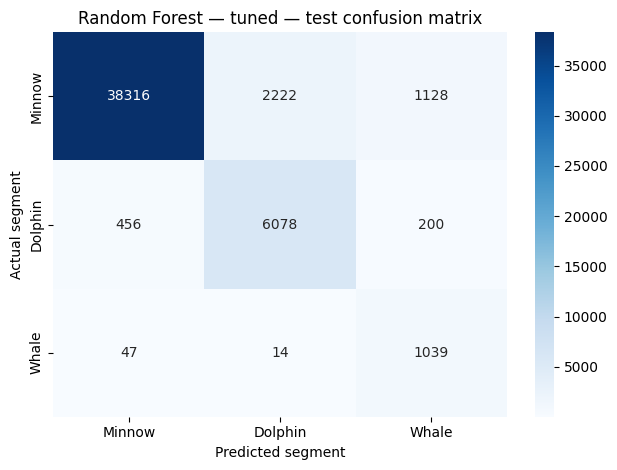

In [18]:
# Evaluate the selected Random Forest on the untouched test set.
y_pred_rf = best_rf.predict(X_test)
rf_scores = evaluate_model("Random Forest — tuned", y_test, y_pred_rf)

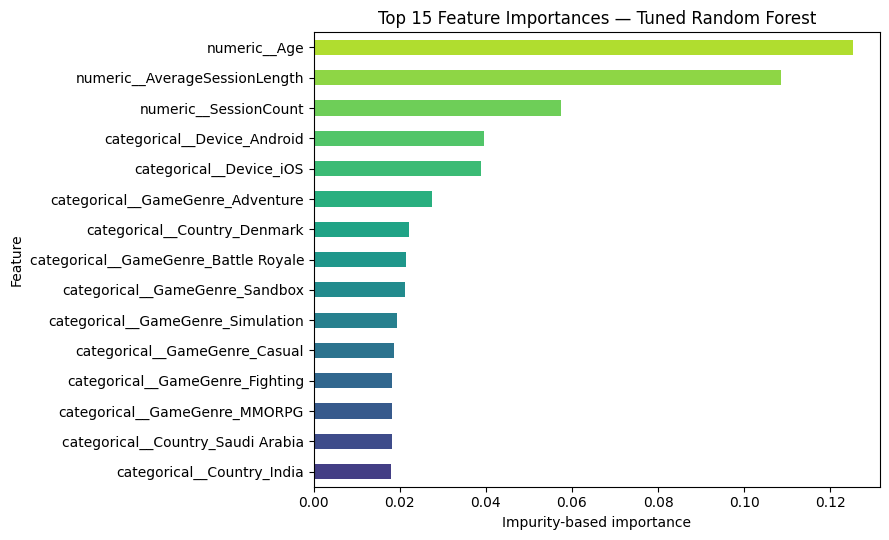

In [19]:
rf_names =best_rf.named_steps["preprocess"].get_feature_names_out()
rf_importance = pd.Series(best_rf.named_steps["model"].feature_importances_, index=rf_names).sort_values(ascending=False).head(15)
plot_importance(rf_importance, "Top 15 Feature Importances — Tuned Random Forest", "Impurity-based importance", cmap="viridis", figsize=(9, 5.5))

In [20]:
rf_comparison =pd.DataFrame([rf_base_scores, rf_scores]).set_index("Model")
print("\nRandom Forest before/after tuning:")
print(rf_comparison.round(4).to_string())


Random Forest before/after tuning:
                          Accuracy  Balanced Accuracy  Macro-F1
Model                                                          
Random Forest — baseline    0.8609             0.8784    0.6753
Random Forest — tuned       0.9178             0.9222    0.7864


## Model 4: NLP Classifier (Tabular-to-Text TF-IDF + Logistic Regression)

This supplementary experiment converts the same selected profile and session fields into short text and applies TF-IDF with Logistic Regression. It is included as a representation comparison; these are structured records rather than naturally occurring text. The vectorizer remains inside the pipeline so vocabulary is learned only from the training portion of each cross-validation fold.

In [21]:
# Convert only the explicit predictor set into text; do not include the target or excluded generated fields.
def make_profile_text(frame):
    text_frame = frame[FEATURE_COLS].copy().fillna("Unknown").astype(str)
    return text_frame.apply(
        lambda row: " ".join(f"{column} {row[column]}" for column in FEATURE_COLS),
        axis=1,
    )

X_train_text = make_profile_text(X_train)
X_test_text = make_profile_text(X_test)
nlp_pipeline = Pipeline(steps=[
    ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), max_features=5000, min_df=5)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
])
nlp_cv_scores = cross_val_score(
    nlp_pipeline, X_train_text, y_train, cv=cv, scoring="f1_macro", n_jobs=-1
)
print(f"TF-IDF Logistic Regression 3-fold CV Macro-F1: {nlp_cv_scores.mean():.4f} (+/- {nlp_cv_scores.std():.4f})")

TF-IDF Logistic Regression 3-fold CV Macro-F1: 0.3017 (+/- 0.0013)


TF-IDF + Logistic Regression
                    0.430162
                    0.463019
                    0.301831

Classification report:
              precision    recall  f1-score   support

      Minnow     0.8761    0.4322    0.5789     41666
     Dolphin     0.1762    0.3959    0.2438      6734
       Whale     0.0447    0.5609    0.0828      1100

    accuracy                         0.4302     49500
   macro avg     0.3657    0.4630    0.3018     49500
weighted avg     0.7624    0.4302    0.5223     49500



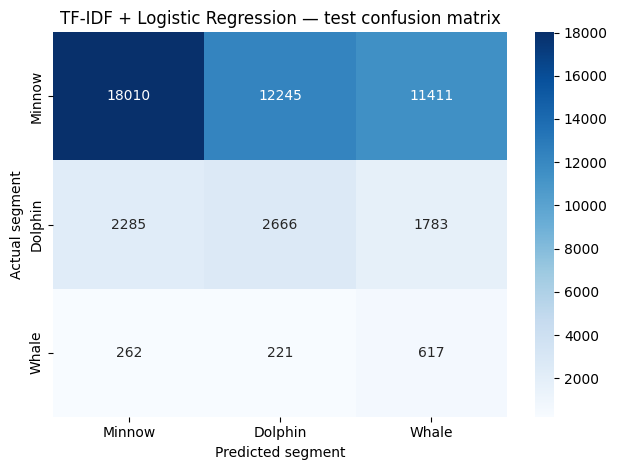

In [22]:
nlp_pipeline.fit(X_train_text, y_train)
y_pred_nlp = nlp_pipeline.predict(X_test_text)
nlp_scores = evaluate_model("TF-IDF + Logistic Regression", y_test, y_pred_nlp)

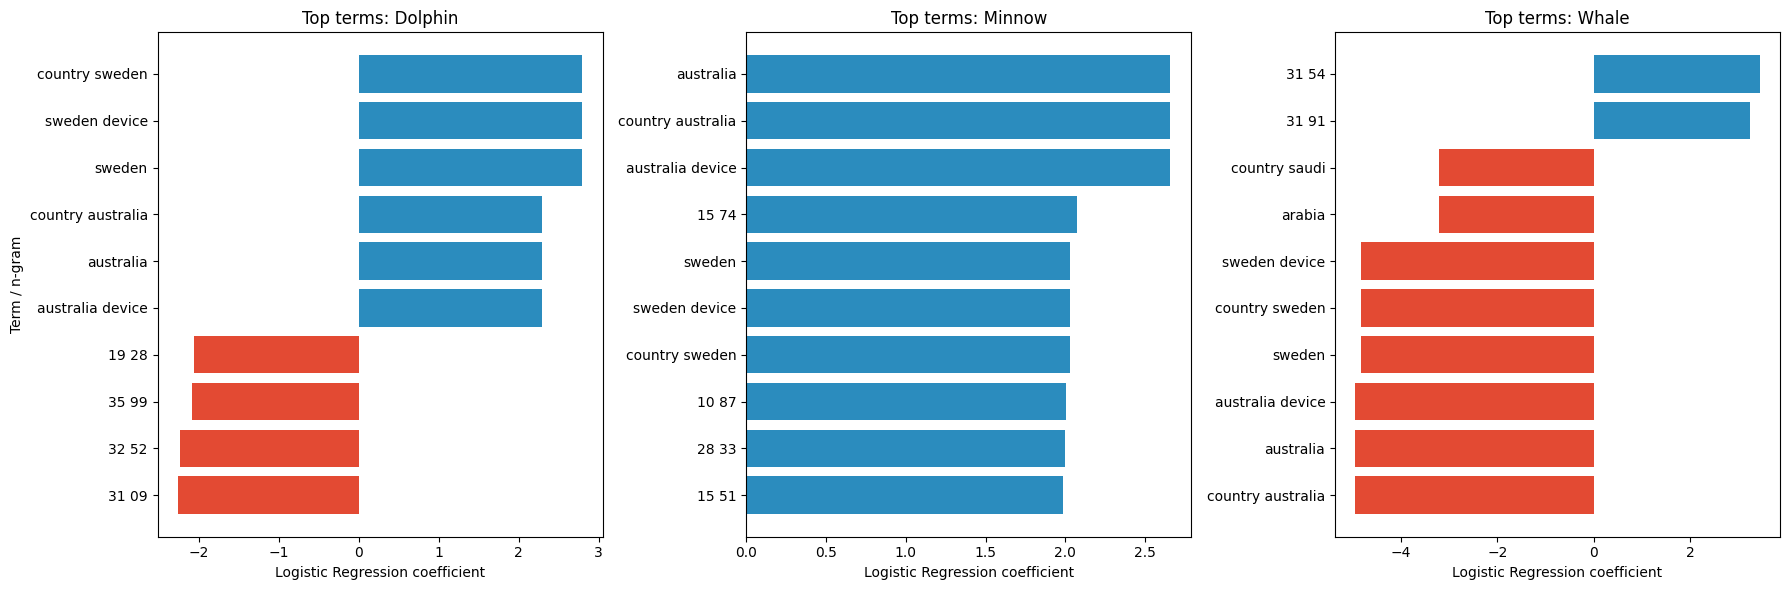

In [23]:
# The largest positive/negative coefficients describe term association, not causal effects.
vectorizer = nlp_pipeline.named_steps["tfidf"]
classifier = nlp_pipeline.named_steps["clf"]
terms = np.array(vectorizer.get_feature_names_out())
fig, axes = plt.subplots(1, len(classifier.classes_), figsize=(18, 6), sharex=False)
for index, label in enumerate(classifier.classes_):
    coefficients = classifier.coef_[index]
    top = np.argsort(np.abs(coefficients))[-10:]
    order = top[np.argsort(coefficients[top])]
    colors = np.where(coefficients[order] >= 0, "#2b8cbe", "#e34a33")
    axes[index].barh(terms[order], coefficients[order], color=colors)
    axes[index].set_title(f"Top terms: {label}")
    axes[index].set_xlabel("Logistic Regression coefficient")
    if index == 0:
        axes[index].set_ylabel("Term / n-gram")
plt.tight_layout()
plt.show()

## Interpretation and Comparison

Compare the recalculated test metrics with the Decision Tree, XGBoost, and Dummy results. The TF-IDF approach is supplementary because turning numeric fields into text can discard useful numeric structure. Select a final classifier using cross-validation Macro-F1 together with class-specific test performance and business error costs. Feature and term importance are associations, not causal evidence; the synthetic data and lack of row-lineage identifiers limit generalization claims.

In [24]:
model_comparison = pd.DataFrame([rf_base_scores, rf_scores, nlp_scores]).set_index("Model")
print("Random Forest and TF-IDF held-out test results:")
print(model_comparison.round(4).to_string())

Random Forest and TF-IDF held-out test results:
                              Accuracy  Balanced Accuracy  Macro-F1
Model                                                              
Random Forest — baseline        0.8609             0.8784    0.6753
Random Forest — tuned           0.9178             0.9222    0.7864
TF-IDF + Logistic Regression    0.4302             0.4630    0.3018


## Baseline Comparison (Dummy Classifier)

A majority-class Dummy model provides a reference point for interpreting accuracy under class imbalance. It uses the same training and test records as the other models.

In [25]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

Dummy — majority class
              0.841737
              0.333333
               0.30469

Classification report:
              precision    recall  f1-score   support

      Minnow     0.8417    1.0000    0.9141     41666
     Dolphin     0.0000    0.0000    0.0000      6734
       Whale     0.0000    0.0000    0.0000      1100

    accuracy                         0.8417     49500
   macro avg     0.2806    0.3333    0.3047     49500
weighted avg     0.7085    0.8417    0.7694     49500



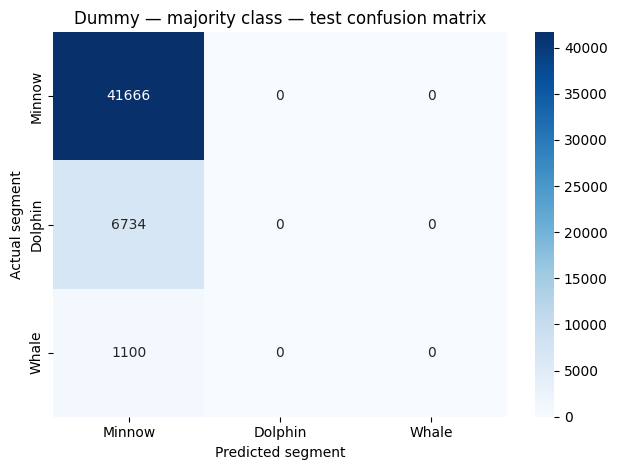

In [26]:
# Test-set results: majority-class Dummy baseline.
dummy_scores = evaluate_model("Dummy — majority class", y_test, y_pred_dummy)

In [27]:
# Cross-model comparison using the same held-out test split.
model_comparison = pd.DataFrame([
    dummy_scores,
    gini_scores,
    entropy_scores,
    dt_scores,
    xgb_reference_scores,
    xgb_scores,
    rf_base_scores,
    rf_scores,
    nlp_scores,
]).set_index("Model").sort_values("Macro-F1", ascending=False)
print("All-model held-out test comparison:")
print(model_comparison.round(4).to_string())

All-model held-out test comparison:
                                   Accuracy  Balanced Accuracy  Macro-F1
Model                                                                   
Decision Tree — Gini (untuned)       0.9462             0.8623    0.8665
Decision Tree — Entropy (untuned)    0.9429             0.8585    0.8603
Random Forest — tuned                0.9178             0.9222    0.7864
XGBoost — tuned                      0.8815             0.9188    0.7651
Random Forest — baseline             0.8609             0.8784    0.6753
XGBoost — untuned reference          0.7093             0.8061    0.5363
Decision Tree — tuned                0.5860             0.6568    0.4249
Dummy — majority class               0.8417             0.3333    0.3047
TF-IDF + Logistic Regression         0.4302             0.4630    0.3018
